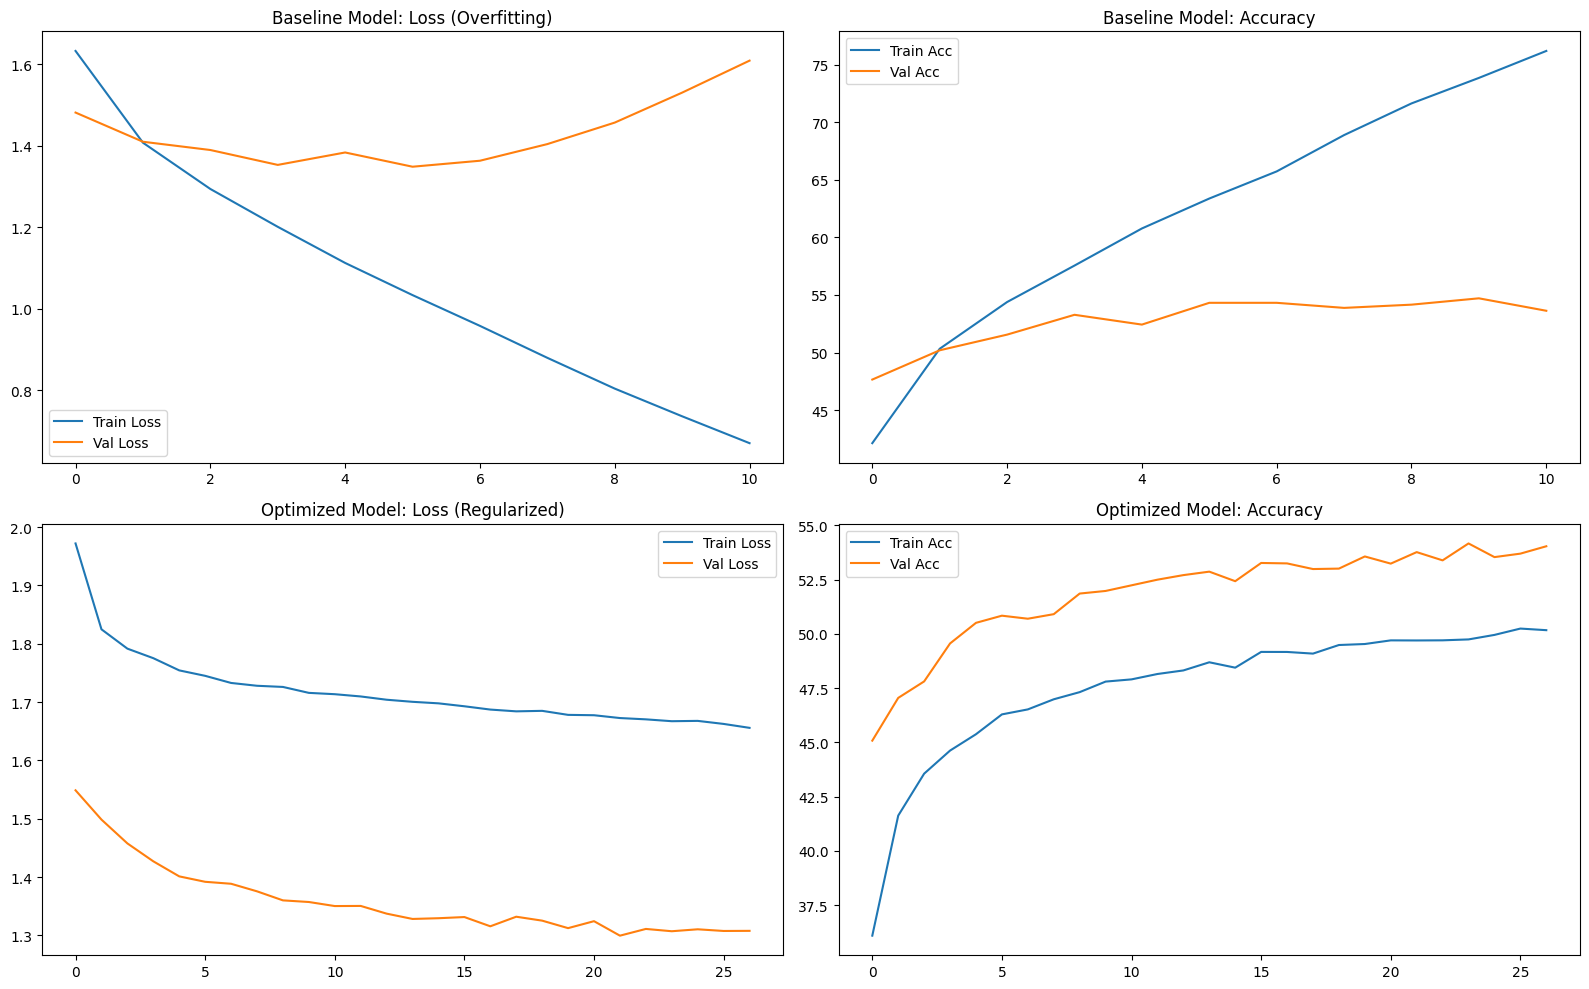

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

class BaselineModel(nn.Module):
    def __init__(self):
        super(BaselineModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, 512)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

class OptimizedModel(nn.Module):
    def __init__(self):
        super(OptimizedModel, self).__init__()
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 32 * 3, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(0.5)

        self.fc2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(0.5)

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.drop1(self.relu1(self.bn1(self.fc1(x))))
        x = self.drop2(self.relu2(self.bn2(self.fc2(x))))
        return self.fc3(x)

class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

def train_and_evaluate(model, optimizer, epochs=30, use_l1=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    early_stopping = EarlyStopping(patience=5)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss, correct, total = 0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            if use_l1:
                l1_penalty = sum(p.abs().sum() for p in model.parameters())
                loss += 1e-5 * l1_penalty

            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        history['train_loss'].append(train_loss / len(train_loader))
        history['train_acc'].append(100. * correct / total)

        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_loss_epoch = val_loss / len(test_loader)
        history['val_loss'].append(val_loss_epoch)
        history['val_acc'].append(100. * correct / total)

        early_stopping(val_loss_epoch)
        if early_stopping.early_stop:
            break

    return history

def plot_curves(base_hist, opt_hist):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    axes[0, 0].plot(base_hist['train_loss'], label='Train Loss')
    axes[0, 0].plot(base_hist['val_loss'], label='Val Loss')
    axes[0, 0].set_title('Baseline Model: Loss (Overfitting)')
    axes[0, 0].legend()

    axes[0, 1].plot(base_hist['train_acc'], label='Train Acc')
    axes[0, 1].plot(base_hist['val_acc'], label='Val Acc')
    axes[0, 1].set_title('Baseline Model: Accuracy')
    axes[0, 1].legend()

    axes[1, 0].plot(opt_hist['train_loss'], label='Train Loss')
    axes[1, 0].plot(opt_hist['val_loss'], label='Val Loss')
    axes[1, 0].set_title('Optimized Model: Loss (Regularized)')
    axes[1, 0].legend()

    axes[1, 1].plot(opt_hist['train_acc'], label='Train Acc')
    axes[1, 1].plot(opt_hist['val_acc'], label='Val Acc')
    axes[1, 1].set_title('Optimized Model: Accuracy')
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()

baseline_model = BaselineModel()
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

optimized_model = OptimizedModel()
optimized_optimizer = optim.Adam(optimized_model.parameters(), lr=0.001, weight_decay=1e-4)

if __name__ == "__main__":
    base_history = train_and_evaluate(baseline_model, baseline_optimizer, epochs=30, use_l1=False)
    opt_history = train_and_evaluate(optimized_model, optimized_optimizer, epochs=30, use_l1=True)
    plot_curves(base_history, opt_history)